# Machine Learning for Identifying Women-Safety Hotspots and Patterns: Ekurhuleni and Kempton Park

**Student number:** 22328534  
**Surname:** Mnyayi  
**Initials:** OR



## 1. Aim and research questions

This project explores recorded crime patterns in Ekurhuleni, with particular attention to Kempton Park. It identifies police-station/year observations with relatively high recorded crime counts, examines patterns in selected safety-related categories, and trains a simple classifier to reproduce a transparent hotspot rule.



## 2. Datasets and alignment

Dataset 1: South African Police Service (SAPS), South African Police Service Annual Crime Records 2005-2026, version 1.5, distributed by DataFirst. DOI: https://doi.org/10.25828/5MAW-4H90. The dataset has yearly crime counts (per financial year) for each police station, along with the local municipality, district municipality, coordinates and crime categories. Each row is a total for one station in one year, so it’s not a list of individual incidents.

Dataset 2: Statistics South Africa ward-level small-area population estimates. I downloaded the workbook extracts for age group, population group and sex (the files are dated 27-10-2025). The sex workbook also has municipal totals on top of the ward estimates. The municipal table gives the total, female and male estimates for Ekurhuleni, but the ward-level estimates can’t be joined straight to the police-station boundaries.

Limitations: The SAPS categories are reported counts, so they can be affected by under-reporting, how crimes are recorded, how the categories are defined, and changes to station boundaries. The records also don’t include the sex of victims, the exact coordinates of incidents, or the dates of incidents within a year. The latest financial-year label should be checked against the source’s release notes before treating it as a complete year.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, precision_score, recall_score, f1_score
import zipfile

DATA_DIR = Path("data")
CRIME_FILE = DATA_DIR / "/content/data/sapacr-2005-2026-v1.5.zip"
SEX_FILE = DATA_DIR / "/content/data/sapacr-2005-2026-v1.5.zip"

# Open the ZIP archive and read the specific CSV file inside it
with zipfile.ZipFile(CRIME_FILE, 'r') as z:
    with z.open('sapacr-2005-2026-v1.5.csv') as f:
        crime = pd.read_csv(f, low_memory=False)

print("Raw dataset shape:", crime.shape)
print("Columns:", crime.columns.tolist())
crime.head()

Raw dataset shape: (24316, 38)
Columns: ['year', 'station', 'loc_mn', 'dc_mn', 'longitude', 'latitude', 'dui', 'drug_crime', 'illegal_firearms', 'malicious_damage', 'arson', 'bank_robbery', 'burglary_nonres', 'burglary_res', 'carjacking', 'truck_hijacking', 'commercial_crime', 'common_assault', 'assault_gbh', 'robbery_nonres', 'robbery_res', 'cash_transit_robbery', 'aggr_robbery', 'common_robbery', 'murder', 'attempted_murder', 'attempted_sexoff', 'rape', 'sexual_assault', 'police_detected_sexoff', 'contact_sexoff', 'sexual_offences', 'kidnapping', 'shoplifting', 'stock_theft', 'vehicle_theft', 'theft_from_vehicle', 'other_theft']


,year,station,loc_mn,dc_mn,longitude,latitude,dui,drug_crime,illegal_firearms,malicious_damage,...,sexual_assault,police_detected_sexoff,contact_sexoff,sexual_offences,kidnapping,shoplifting,stock_theft,vehicle_theft,theft_from_vehicle,other_theft
0,2005/2006,aberdeen,dr beyers naude,sarah baartman,"23,8712379454244","-32,5967545437703",2,12,0,26,...,0.0,0,NaN,0,0,3,46,0,9.0,63
1,2005/2006,acornhoek,bushbuckridge,ehlanzeni,"30,9975703031244","-24,6230113831757",1,23,19,149,...,0.0,0,0.0,0,0,84,15,17,24.0,223
2,2005/2006,actonville,ekurhuleni,ekurhuleni,"28,3056180857924","-26,2199687974063",28,55,10,121,...,0.0,0,0.0,0,4,5,0,95,69.0,150
3,2005/2006,addo,sundays river valley,sarah baartman,"25,668585191722","-33,5451593189792",7,6,1,42,...,0.0,0,NaN,0,0,3,26,13,16.0,153
4,2005/2006,adelaide,raymond mhlaba,amathole,"26,2928437206771","-32,6717099958241",2,7,1,36,...,0.0,0,0.0,0,1,13,68,5,15.0,85


## 3. Data quality checks and cleaning

In [ ]:

for col in ["station", "loc_mn", "dc_mn", "year"]:
    crime[col] = crime[col].astype("string").str.strip()

for col in ["longitude", "latitude"]:
    crime[col] = pd.to_numeric(crime[col].astype("string").str.replace(",", ".", regex=False), errors="coerce")

id_cols = ["year", "station", "loc_mn", "dc_mn", "longitude", "latitude"]
crime_cols = [c for c in crime.columns if c not in id_cols]
for col in crime_cols:
    crime[col] = pd.to_numeric(crime[col], errors="coerce")

print("Duplicate rows:", int(crime.duplicated().sum()))
missing = crime.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_values"))
print("Coordinate rows missing either coordinate:", int(crime[["longitude", "latitude"]].isna().any(axis=1).sum()))
print("Crime category count columns:", len(crime_cols))

crime["total_recorded_crimes"] = crime[crime_cols].fillna(0).sum(axis=1)
crime["station_key"] = crime["station"].str.lower().str.strip()
crime["municipality_key"] = crime["loc_mn"].str.lower().str.strip()

print("Financial years:", crime["year"].nunique(), "from", crime["year"].min(), "to", crime["year"].max())
print("Exact duplicate rows after cleaning:", int(crime.duplicated().sum()))

Duplicate rows: 0


,missing_values
rape,443
contact_sexoff,388
longitude,378
latitude,378
dc_mn,378
loc_mn,378
sexual_assault,252
attempted_sexoff,123
theft_from_vehicle,1


Coordinate rows missing either coordinate: 378
Crime category count columns: 32
Financial years: 21 from 2005/2006 to 2025/2026
Exact duplicate rows after cleaning: 0


## 4. Describe the data

Ekurhuleni rows: 756
Unique stations: 36
Financial years: 21


,year,station,loc_mn,longitude,latitude,total_recorded_crimes
2,2005/2006,actonville,ekurhuleni,28.305618,-26.219969,1714.0
9,2005/2006,alberton,ekurhuleni,28.13997,-26.284027,7299.0
53,2005/2006,bedfordview,ekurhuleni,28.154703,-26.166956,5024.0
64,2005/2006,benoni,ekurhuleni,28.334452,-26.167164,8713.0
90,2005/2006,boksburg,ekurhuleni,28.259105,-26.23963,3739.0


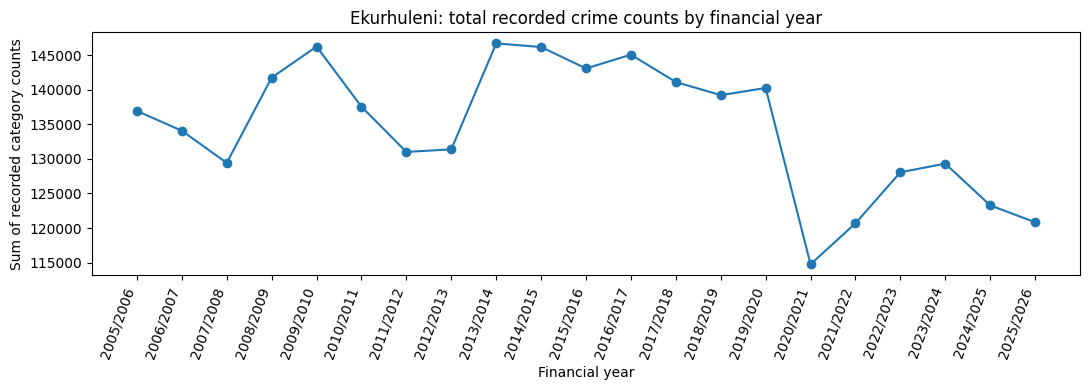

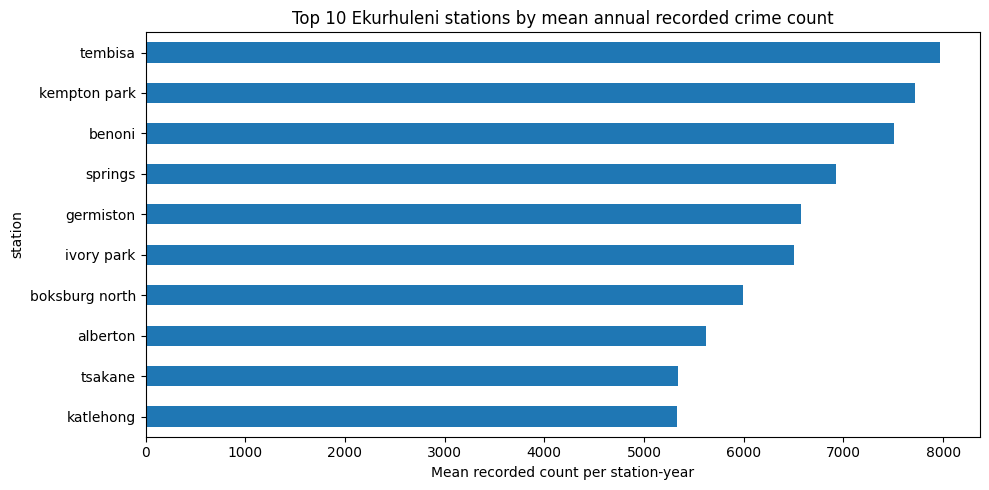

In [ ]:
ek = crime[crime["municipality_key"].eq("ekurhuleni")].copy()
if ek.empty:
    raise ValueError("No rows matched loc_mn='ekurhuleni'. Inspect municipality labels above.")
print("Ekurhuleni rows:", len(ek))
print("Unique stations:", ek["station"].nunique())
print("Financial years:", ek["year"].nunique())
display(ek[["year", "station", "loc_mn", "longitude", "latitude", "total_recorded_crimes"]].head())

yearly = ek.groupby("year", as_index=False)["total_recorded_crimes"].sum()
plt.figure(figsize=(11, 4))
plt.plot(yearly["year"], yearly["total_recorded_crimes"], marker="o")
plt.xticks(rotation=70, ha="right")
plt.title("Ekurhuleni: total recorded crime counts by financial year")
plt.xlabel("Financial year")
plt.ylabel("Sum of recorded category counts")
plt.tight_layout()
plt.show()

top_station_avg = ek.groupby("station")["total_recorded_crimes"].mean().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 5))
top_station_avg.sort_values().plot(kind="barh")
plt.title("Top 10 Ekurhuleni stations by mean annual recorded crime count")
plt.xlabel("Mean recorded count per station-year")
plt.tight_layout()
plt.show()

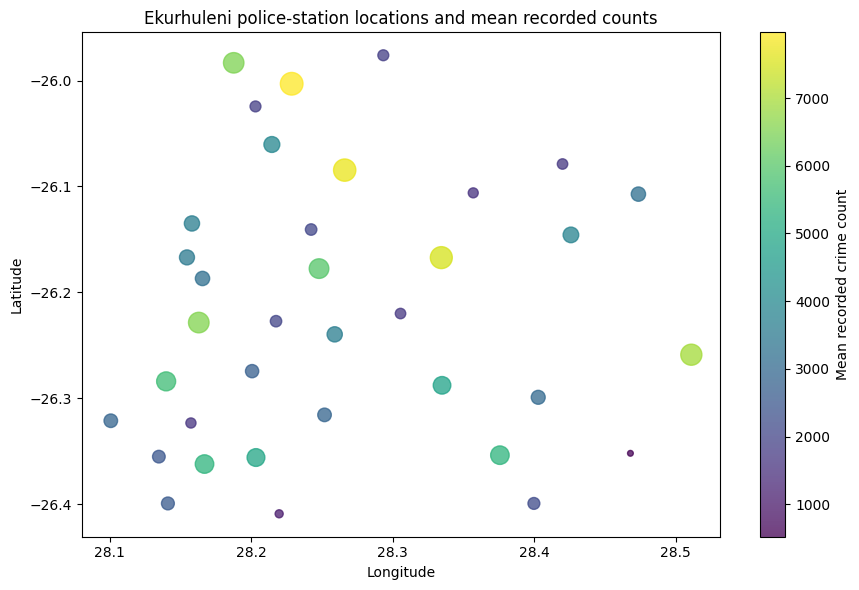

Stations plotted: 36


In [18]:

# Spatial overview of police-station locations
spatial = ek.dropna(subset=["longitude", "latitude"]).copy()

station_locations = spatial.groupby("station", as_index=False).agg(
    longitude=("longitude", "median"),
    latitude=("latitude", "median"),
    mean_recorded_crimes=("total_recorded_crimes", "mean")
)

plt.figure(figsize=(9, 6))
points = plt.scatter(
    station_locations["longitude"],
    station_locations["latitude"],
    c=station_locations["mean_recorded_crimes"],
    s=station_locations["mean_recorded_crimes"].clip(lower=1) / 30,
    alpha=0.75
)

plt.colorbar(points, label="Mean recorded crime count")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Ekurhuleni police-station locations and mean recorded counts")
plt.tight_layout()
plt.show()

print("Stations plotted:", len(station_locations))

This spatial overview plots police-station coordinates and colours the points according to mean recorded crime counts. It shows the locations of police stations, not the exact locations of individual incidents. Therefore, it is a spatial overview rather than an incident-level hotspot map.


This spatial overview plots police-station coordinates and colours the points according to mean recorded crime counts. It shows the locations of police stations, not the exact locations of individual incidents. Therefore, it is a spatial overview rather than an incident-level hotspot map.

## 5. Hotspot definition

For this baseline, a **hotspot** is a station-year record whose total recorded crime count is at or above the 75th percentile of total recorded crime counts among Ekurhuleni station-year records. This transparent relative threshold identifies the upper quarter of observations for comparison. It is not a validated danger threshold and does not measure an individual's risk.

Because the dataset lacks a compatible station-catchment population denominator, counts are used rather than population-adjusted rates. The target label is derived from the same dataset, so model metrics below measure how well the classifier reproduces this rule—not independent proof that a location is objectively unsafe.

In [ ]:
threshold = ek["total_recorded_crimes"].quantile(0.75)
ek["hotspot"] = (ek["total_recorded_crimes"] >= threshold).astype(int)
print(f"75th-percentile threshold: {threshold:,.2f}")
print("Hotspot records:", int(ek["hotspot"].sum()), "of", len(ek), f"({ek['hotspot'].mean():.1%})")
display(ek.groupby("hotspot")["total_recorded_crimes"].agg(["count", "min", "median", "mean", "max"]))

75th-percentile threshold: 5,184.25
Hotspot records: 189 of 756 (25.0%)


,count,min,median,mean,max
hotspot,,,,,
0,567,0.0,2661.0,2694.435626,5184.0
1,189,5185.0,6827.0,6872.391534,9510.0


## 6. Pattern Discovery

,sum_of_station_year_counts
common_assault,232122.0
aggr_robbery,231137.0
assault_gbh,204278.0
sexual_offences,53144.0
rape,40515.0
kidnapping,14903.0
sexual_assault,6738.0
attempted_sexoff,2076.0


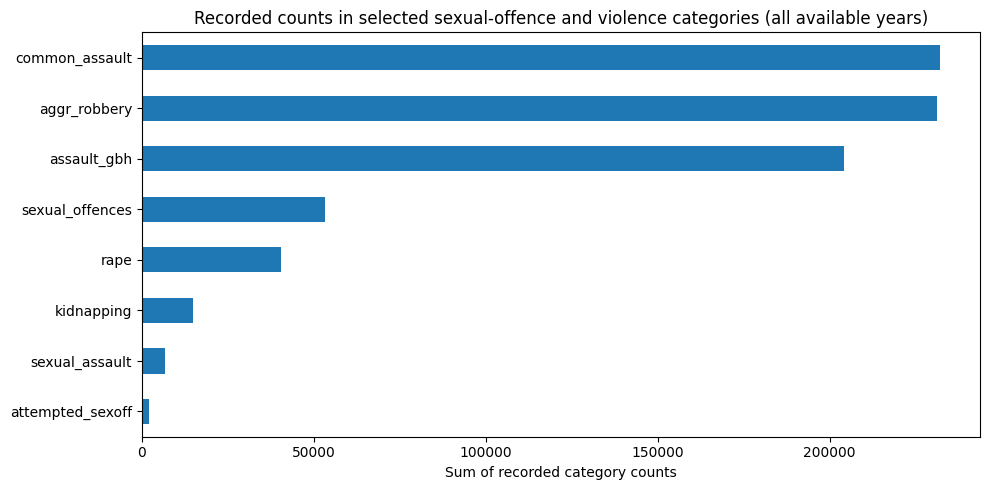

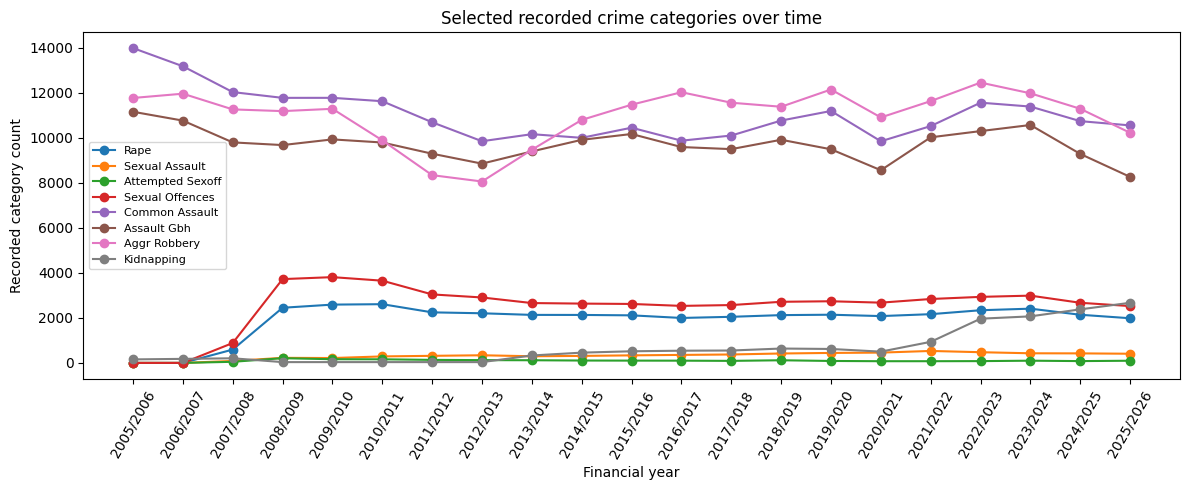

In [19]:
candidate_categories = ["rape", "sexual_assault", "attempted_sexoff", "sexual_offences",
                       "common_assault", "assault_gbh", "aggr_robbery", "kidnapping"]
available_categories = [c for c in candidate_categories if c in ek.columns]
category_summary = ek[available_categories].fillna(0).sum().sort_values(ascending=False)
display(category_summary.to_frame("sum_of_station_year_counts"))

plt.figure(figsize=(10, 5))
category_summary.sort_values().plot(kind="barh")
plt.title("Recorded counts in selected sexual-offence and violence categories (all available years)")
plt.xlabel("Sum of recorded category counts")
plt.tight_layout()
plt.show()


# Selected category trends by financial year
if available_categories:
    category_yearly = ek.groupby("year")[available_categories].sum(min_count=1)

    plt.figure(figsize=(12, 5))
    for category in available_categories:
        plt.plot(
            category_yearly.index,
            category_yearly[category],
            marker="o",
            label=category.replace("_", " ").title()
        )

    plt.xlabel("Financial year")
    plt.ylabel("Recorded category count")
    plt.title("Selected recorded crime categories over time")
    plt.xticks(rotation=60)
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    print("No selected category columns were found.")


# These categories are not confirmed to be victim-sex-specific.


## 7. Compare three station areas

,mean_annual_total,latest_year,years_observed,mean_rape,mean_sexual_assault,mean_common_assault,mean_assault_gbh
station,,,,,,,
tembisa,7971.90,2025/2026,21,176.11,12.57,799.48,759.57
kempton park,7723.29,2025/2026,21,41.90,12.75,441.29,203.48
benoni,7502.90,2025/2026,21,65.00,16.30,475.38,304.38


Selected stations: ['tembisa', 'kempton park', 'benoni']
Kempton Park included: True


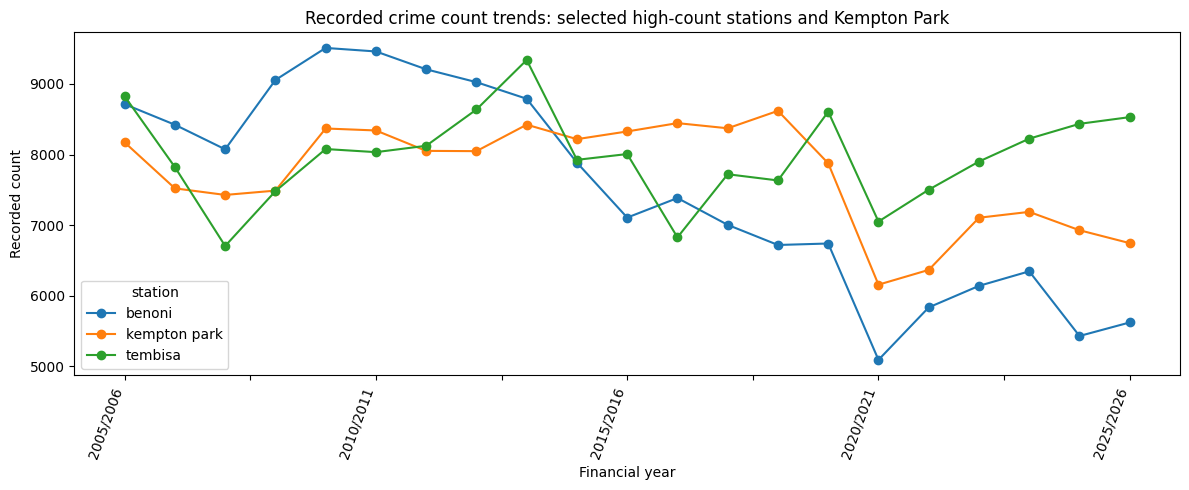


--- Spatial overview of police stations ---


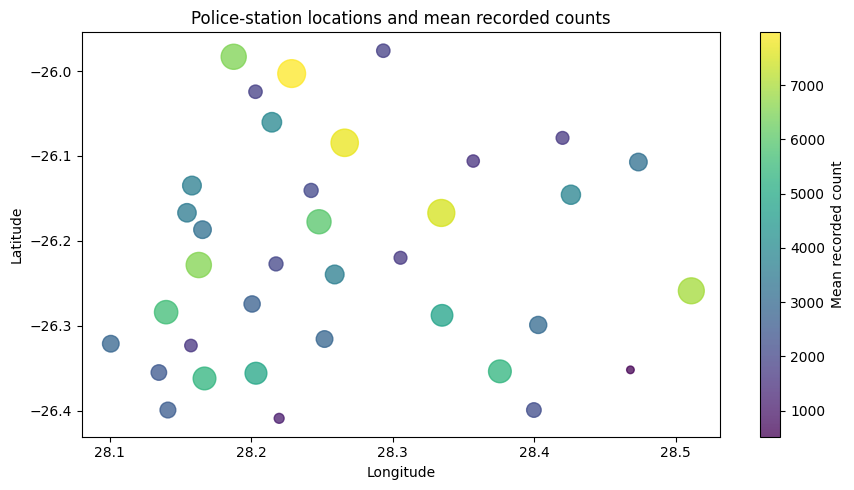

Note: Station locations are shown, not individual incident locations. Recorded counts are not population-adjusted rates.


In [21]:
# Select the three station areas with the highest mean annual total counts, based on observed data.
selected_stations = ek.groupby("station")["total_recorded_crimes"].mean().sort_values(ascending=False).head(3).index.tolist()
comparison = ek[ek["station"].isin(selected_stations)].groupby("station").agg(
    mean_annual_total=("total_recorded_crimes", "mean"),
    latest_year=("year", "max"),
    years_observed=("year", "nunique"),
    mean_rape=("rape", "mean"),
    mean_sexual_assault=("sexual_assault", "mean"),
    mean_common_assault=("common_assault", "mean"),
    mean_assault_gbh=("assault_gbh", "mean")
).sort_values("mean_annual_total", ascending=False)
display(comparison.round(2))
print("Selected stations:", selected_stations)
print("Kempton Park included:", any("kempton park" == s.lower() for s in selected_stations))

# compare with the three highest-mean stations
focus_stations = list(dict.fromkeys(selected_stations + (["kempton park"] if "kempton park" in set(ek["station"].str.lower()) else [])))
focus = ek[ek["station"].str.lower().isin(focus_stations)]
focus_yearly = focus.pivot_table(index="year", columns="station", values="total_recorded_crimes", aggfunc="sum")
ax = focus_yearly.plot(figsize=(12, 5), marker="o")
ax.set_title("Recorded crime count trends: selected high-count stations and Kempton Park")
ax.set_xlabel("Financial year")
ax.set_ylabel("Recorded count")
plt.xticks(rotation=70, ha="right")
plt.tight_layout()
plt.show()


print("\n--- Spatial overview of police stations ---")

spatial = ek.dropna(
    subset=["longitude", "latitude"]
).groupby("station", as_index=False).agg(
    longitude=("longitude", "median"),
    latitude=("latitude", "median"),
    mean_recorded_crimes=("total_recorded_crimes", "mean")
)

if not spatial.empty:
    fig, ax = plt.subplots(figsize=(9, 5))

    points = ax.scatter(
        spatial["longitude"],
        spatial["latitude"],
        c=spatial["mean_recorded_crimes"],
        s=np.clip(
            spatial["mean_recorded_crimes" ] /
            max(spatial["mean_recorded_crimes"].max(), 1) * 400,
            30, 400
        ),
        alpha=0.75
    )

    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title("Police-station locations and mean recorded counts")
    fig.colorbar(points, ax=ax, label="Mean recorded count")
    fig.tight_layout()
    plt.show()

    print(
        "Note: Station locations are shown, not individual incident locations. "
        "Recorded counts are not population-adjusted rates."
    )
else:
    print("Warning: No valid station coordinates are available for these filters.")

## 8. Machine-learning classifier and evaluation

A Random Forest classifier uses the crime-category count columns to predict the hotspot label. The label is defined using total counts, so there is an inherent limitation: the model is learning a label derived from the same underlying category counts. This is a baseline demonstration of supervised classification, not an independent forecast of women's safety. A random train/test split is used here for a simple baseline; a later, stronger design could hold out the most recent financial years to assess temporal generalisation.

,accuracy,precision_hotspot,recall_hotspot,f1_hotspot
0,0.974,1.0,0.894,0.944


              precision    recall  f1-score   support

 Not hotspot       0.97      1.00      0.98       142
     Hotspot       1.00      0.89      0.94        47

    accuracy                           0.97       189
   macro avg       0.98      0.95      0.96       189
weighted avg       0.97      0.97      0.97       189



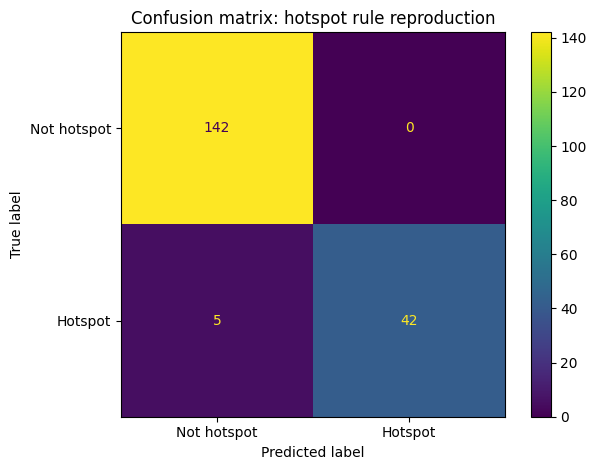

,importance
aggr_robbery,0.164849
robbery_nonres,0.127643
common_assault,0.098064
malicious_damage,0.091041
common_robbery,0.068378
shoplifting,0.068074
other_theft,0.062249
vehicle_theft,0.037023
burglary_nonres,0.031673
commercial_crime,0.027525


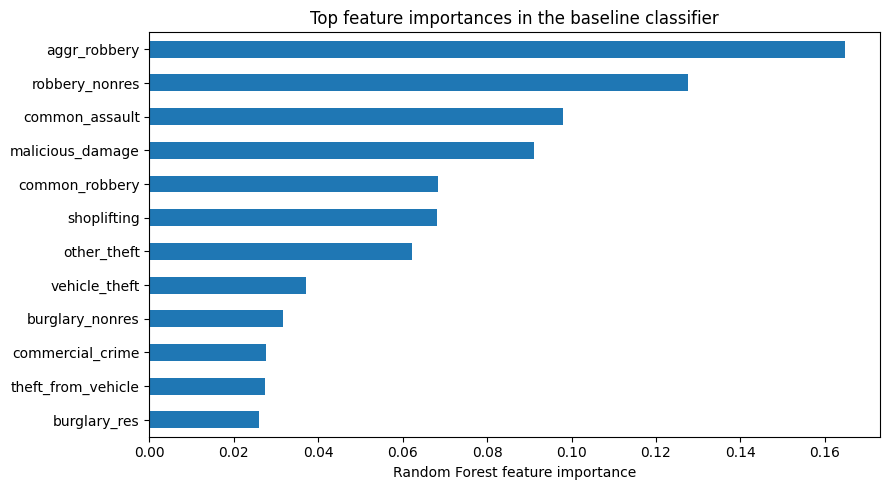

In [ ]:
X = ek[crime_cols].fillna(0)
y = ek["hotspot"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
model = RandomForestClassifier(n_estimators=250, random_state=42, class_weight="balanced")
model.fit(X_train, y_train)
pred = model.predict(X_test)

metrics = {
    "accuracy": accuracy_score(y_test, pred),
    "precision_hotspot": precision_score(y_test, pred, zero_division=0),
    "recall_hotspot": recall_score(y_test, pred, zero_division=0),
    "f1_hotspot": f1_score(y_test, pred, zero_division=0)
}
display(pd.DataFrame([metrics]).round(3))
print(classification_report(y_test, pred, target_names=["Not hotspot", "Hotspot"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Not hotspot", "Hotspot"], cmap=None)
plt.title("Confusion matrix: hotspot rule reproduction")
plt.tight_layout()
plt.show()

importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False).head(12)
display(importance.to_frame("importance"))
plt.figure(figsize=(9, 5))
importance.sort_values().plot(kind="barh")
plt.title("Top feature importances in the baseline classifier")
plt.xlabel("Random Forest feature importance")
plt.tight_layout()
plt.show()

## 9. Population context

In [14]:

import os

for root, folders, files in os.walk("/content"):
    for filename in files:
        if filename.lower().endswith(".zip"):
            print(os.path.join(root, filename))


/content/data/Ward-Product_Locked-spreadsheets.zip
/content/data/sapacr-2005-2026-v1.5.zip


In [15]:

import os
import zipfile

data_folder = "/content/data"

for filename in [
    "Ward-Product_Locked-spreadsheets.zip",
    "sapacr-2005-2026-v1.5.zip"
]:
    zip_path = os.path.join(data_folder, filename)
    extract_folder = os.path.join(
        data_folder, filename.replace(".zip", "")
    )

    os.makedirs(extract_folder, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_folder)

    print(f"Successfully extracted: {filename}")
    print(f"Folder: {extract_folder}")


Successfully extracted: Ward-Product_Locked-spreadsheets.zip
Folder: /content/data/Ward-Product_Locked-spreadsheets
Successfully extracted: sapacr-2005-2026-v1.5.zip
Folder: /content/data/sapacr-2005-2026-v1.5


In [16]:

import os

for root, folders, files in os.walk("/content/data"):
    for filename in files:
        if filename.lower().endswith((".xlsx", ".xls")):
            print(os.path.join(root, filename))


/content/data/Ward-Product_Locked-spreadsheets/Ward Product_Locked spreadsheets/PP_Age Group_27-10-2025.xlsx
/content/data/Ward-Product_Locked-spreadsheets/Ward Product_Locked spreadsheets/PP_Sex_27-10-2025.xlsx
/content/data/Ward-Product_Locked-spreadsheets/Ward Product_Locked spreadsheets/PP_Population Group_27-10-2025.xlsx


In [17]:
# Explicitly point to the Excel population dataset instead of the crime ZIP file
POPULATION_EXCEL_FILE = "/content/data/Ward-Product_Locked-spreadsheets/Ward Product_Locked spreadsheets/PP_Sex_27-10-2025.xlsx"

# The Stats SA sex workbook has municipal totals on the Munic_Total_Sex sheet.
sex_municipal = pd.read_excel(POPULATION_EXCEL_FILE, sheet_name="Munic_Total_Sex")
name_col = sex_municipal.columns[0]
eku_population = sex_municipal[sex_municipal[name_col].astype(str).str.contains("City of Ekurhuleni", case=False, na=False)]
display(eku_population)
if not eku_population.empty:
    print("This municipal estimate is shown for context only. It is not joined to police-station records.")
else:
    print("Ekurhuleni row not found in municipal population sheet; inspect the workbook's labels.")

,Prov/District/Metro/Local municipality,Male,Female,Total
214,EKU City of Ekurhuleni,2.077352e+06,1.989339e+06,4.066691e+06


This municipal estimate is shown for context only. It is not joined to police-station records.


## 10. Interpretation, prevention implications and limitations

**Interpretation template:** The hotspot rule highlights station-year observations in the upper quartile of recorded counts. Compare the selected stations and Kempton Park in terms of total counts and the selected category counts. Do not equate a high count with a higher per-person risk without a valid denominator.

**Possible prevention-planning implications:** local authorities and community safety partners could use these results to decide where to conduct a more detailed, privacy-respecting safety audit; review lighting, transport routes, reporting access, and service availability; and consult local women and community organisations. These are follow-up actions to investigate, not causal conclusions from this dataset.

**Limitations**
- SAPS records are station-year aggregates, not individual incident records.
- Victim sex is not supplied in these crime records; categories cannot automatically be called crimes against women.
- Recorded counts may be influenced by reporting rates, police recording practices, population size, station catchment size and boundary changes.
- No station-catchment population denominator was available/aligned, so no station-level crime rate is claimed.
- Ward population and police-station geographies differ; they were not naively joined.
- Financial-year labels do not provide exact incident dates; the latest year may require source completeness verification.
- The hotspot threshold is relative and chosen for this analysis, not an official SAPS designation.
- Model metrics assess reproduction of the constructed label and should not be interpreted as validation of real-world risk.
- Missing category values were filled with zero only for aggregate totals/model input; if missingness means “not reported” rather than zero, this can bias results.

## 11. Where I got my data from

South African Police Service. (2026). *South African Police Service Annual Crime Records 2005–2026* [dataset], Version 1.5. Pretoria: SAPS; distributed by DataFirst. https://doi.org/10.25828/5MAW-4H90

Statistics South Africa. (2025). *Ward-level small area population estimates* (workbook extracts downloaded 27 October 2025). Cite the exact official Stats SA release/download page required by your lecturer and include it in the final reference list.



In [22]:
%%writefile app.py

import streamlit as st
import pandas as pd

st.set_page_config(
    page_title="Women Safety Hotspot Analysis",
    page_icon="📍",
    layout="wide"
)

st.title("📍 Women Safety Hotspot Analysis")
st.write("Crime pattern analysis for Ekurhuleni and Kempton Park")

st.warning(
    "This dashboard displays recorded crime data. "
    "It does not confirm that every recorded crime involved a woman."
)

uploaded_file = st.file_uploader(
    "Upload your crime dataset (CSV)",
    type=["csv"]
)

if uploaded_file is not None:
    df = pd.read_csv(uploaded_file)

    st.subheader("Dataset Preview")
    st.dataframe(df.head(10), use_container_width=True)

    st.subheader("Dataset Information")
    col1, col2 = st.columns(2)
    col1.metric("Total records", len(df))
    col2.metric("Total columns", len(df.columns))

    numeric_cols = df.select_dtypes(include="number").columns.tolist()

    if numeric_cols:
        category = st.selectbox("Select a crime category", numeric_cols)

        st.subheader("Recorded Crime Counts")
        st.bar_chart(df[category].fillna(0))

        year_cols = [c for c in df.columns if "year" in c.lower()]

        if year_cols:
            year_col = st.selectbox("Select year column", year_cols)
            trend = df.groupby(year_col)[category].sum()
            st.subheader("Crime Trend Over Time")
            st.line_chart(trend)

else:
    st.info("Upload your SAPS crime dataset to view the dashboard.")

Overwriting app.py


In [24]:
!pip -q install streamlit

In [25]:
!pip install streamlit

In [26]:
!streamlit run app.py &>/content/streamlit.log &

In [27]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏
added 22 packages in 2s
⠏
⠏3 packages are looking for funding
⠏  run `npm fund` for details
⠏

In [ ]:
!lt --port 8501

your url is: https://public-mangos-taste.loca.lt
